In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
df = pd.read_csv('/content/Titanic-Dataset.csv')
df = df[['Fare','Pclass','Age','SibSp','Parch']]
df['Age'] = df['Age'].fillna(df['Age'].median())
df= df[df['Fare']>0]

In [3]:
X_simple = df[['Pclass']]
y = df['Fare']
X_tr, X_te, y_tr, y_te = train_test_split(X_simple, y, test_size=0.2, random_state=42)
model_simple = LinearRegression().fit(X_tr, y_tr)
pred_simple = model_simple.predict(X_te)
print('SIMPLE Regression -- Intercept:', round(model_simple.intercept_, 2))
print('SIMPLE Regression -- Slope:', round(model_simple.coef_[0], 2))
print('SIMPLE Regression -- R2:', round(r2_score(y_te, pred_simple), 3))
print('SIMPLE Regression -- RMSE:', round(np.sqrt(mean_squared_error(y_te, pred_simple)),2))

SIMPLE Regression -- Intercept: 112.38
SIMPLE Regression -- Slope: -34.23
SIMPLE Regression -- R2: 0.371
SIMPLE Regression -- RMSE: 35.68


In [4]:
X_multi = df[['Pclass', 'Age', 'SibSp', 'Parch']]
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X_multi, y, test_size=0.2, random_state=42)
model_multi = LinearRegression().fit(X_tr2, y_tr2)
pred_multi = model_multi.predict(X_te2)
print('\nMULTIPLE Regression -- Intercept:', round(model_multi.intercept_, 2))
for name, coef in zip(X_multi.columns, model_multi.coef_):
  print('MULTIPLE Regression -- Coefficient of', name,':',round(coef, 2))
print('MULTIPLE Regression -- R2:', round(r2_score(y_te2, pred_multi), 3))
print("MULTIPLE Regression -- RMSE:", round(np.sqrt(mean_squared_error(y_te2, pred_multi)), 2))


MULTIPLE Regression -- Intercept: 112.3
MULTIPLE Regression -- Coefficient of Pclass : -35.72
MULTIPLE Regression -- Coefficient of Age : -0.12
MULTIPLE Regression -- Coefficient of SibSp : 5.38
MULTIPLE Regression -- Coefficient of Parch : 10.09
MULTIPLE Regression -- R2: 0.462
MULTIPLE Regression -- RMSE: 33.0


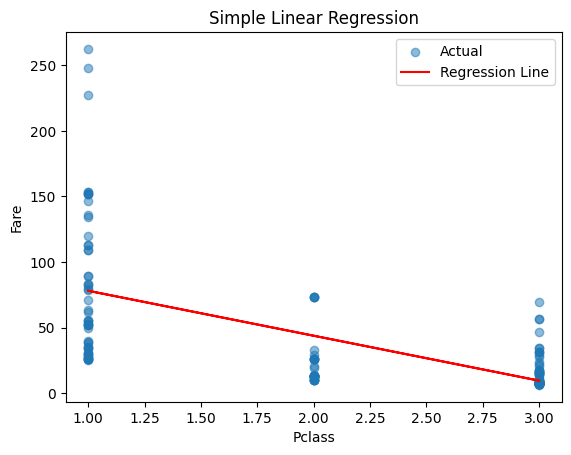

In [8]:
plt.scatter(X_te, y_te, alpha=0.5, label='Actual')
plt.plot(X_te, pred_simple, color='red', label='Regression Line')
plt.xlabel('Pclass'); plt.ylabel('Fare'); plt.title('Simple Linear Regression')
plt.legend()
plt.show()

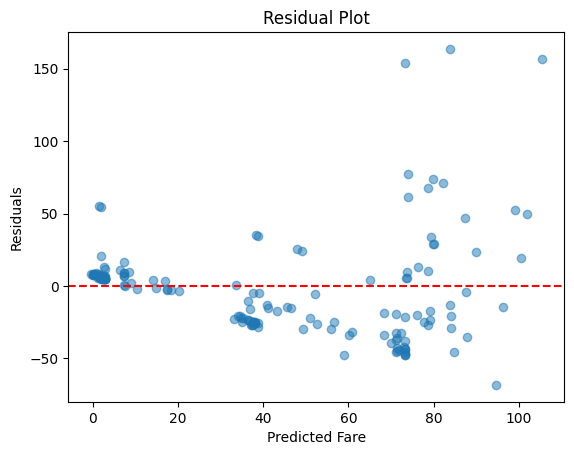

In [7]:
residuals = y_te2 - pred_multi
plt.scatter(pred_multi, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Fare'); plt.ylabel('Residuals'); plt.title('Residual Plot')
plt.show()

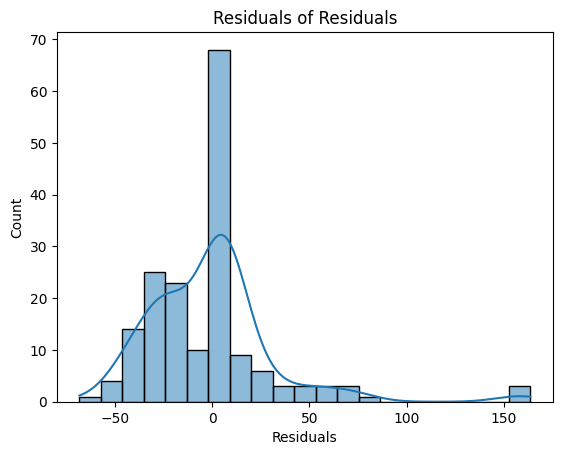

In [10]:
sns.histplot(residuals, kde=True)
plt.xlabel('Residuals');plt.title('Residuals of Residuals')
plt.show()

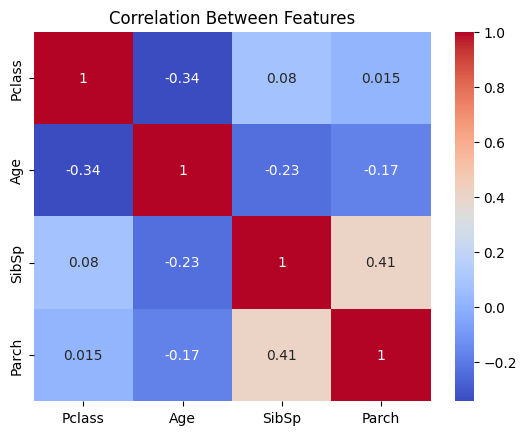

In [11]:
sns.heatmap(X_multi.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Between Features')
plt.show()